# 04 · Uncertainty forecast and Monte Carlo
Separate predicted uncertainty from empirical estimator performance.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "configs" / "baseline.json").exists():
    ROOT = ROOT.parent
if not (ROOT / "configs" / "baseline.json").exists():
    raise RuntimeError("Open this notebook from the project root or notebooks directory")
sys.path.insert(0, str(ROOT / "src"))
from halo_tracking.study import load_config
cfg = load_config(ROOT / "configs" / "baseline.json")


/workspace/scratch/678b6a3ef004/Halo_Orbit_Tracking/src/halo_tracking/study.py:49: UserWarning: Supplied rounded state does not close within 1 km. Treat as an initial-value trajectory, not a validated periodic halo.
  result=make_truth(cfg); result['config']=cfg


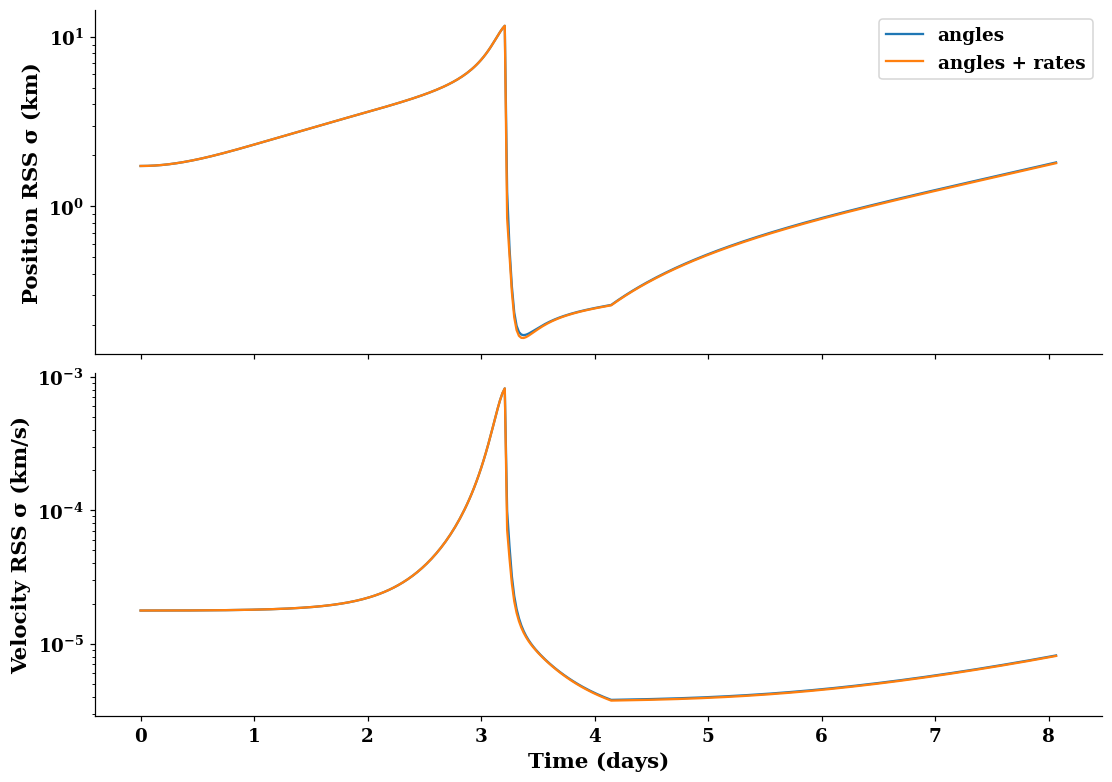

In [2]:
from halo_tracking.study import run_study
from halo_tracking.plotting import uncertainty_comparison
forecast = run_study(cfg, covariance_only=True)
fig = uncertainty_comparison(forecast)

## Small paired Monte Carlo demonstration
Three trials only verify the workflow. Set trials=100 or more for a scientific study, then check convergence with ensemble size. Zero process noise gives deterministic model-matched truth.

In [3]:
from halo_tracking.validation import monte_carlo
mc = monte_carlo(cfg, trials=3)

/workspace/scratch/678b6a3ef004/Halo_Orbit_Tracking/src/halo_tracking/validation.py:12: UserWarning: Supplied rounded state does not close within 1 km. Treat as an initial-value trajectory, not a validated periodic halo.
  base=make_truth(cfg); output={}


angles Final NEES: 21.05968533495412 Visible NIS mean: 2.2648279211559297
angles_rates Final NEES: 28.651499242280778 Visible NIS mean: 4.31156537805613


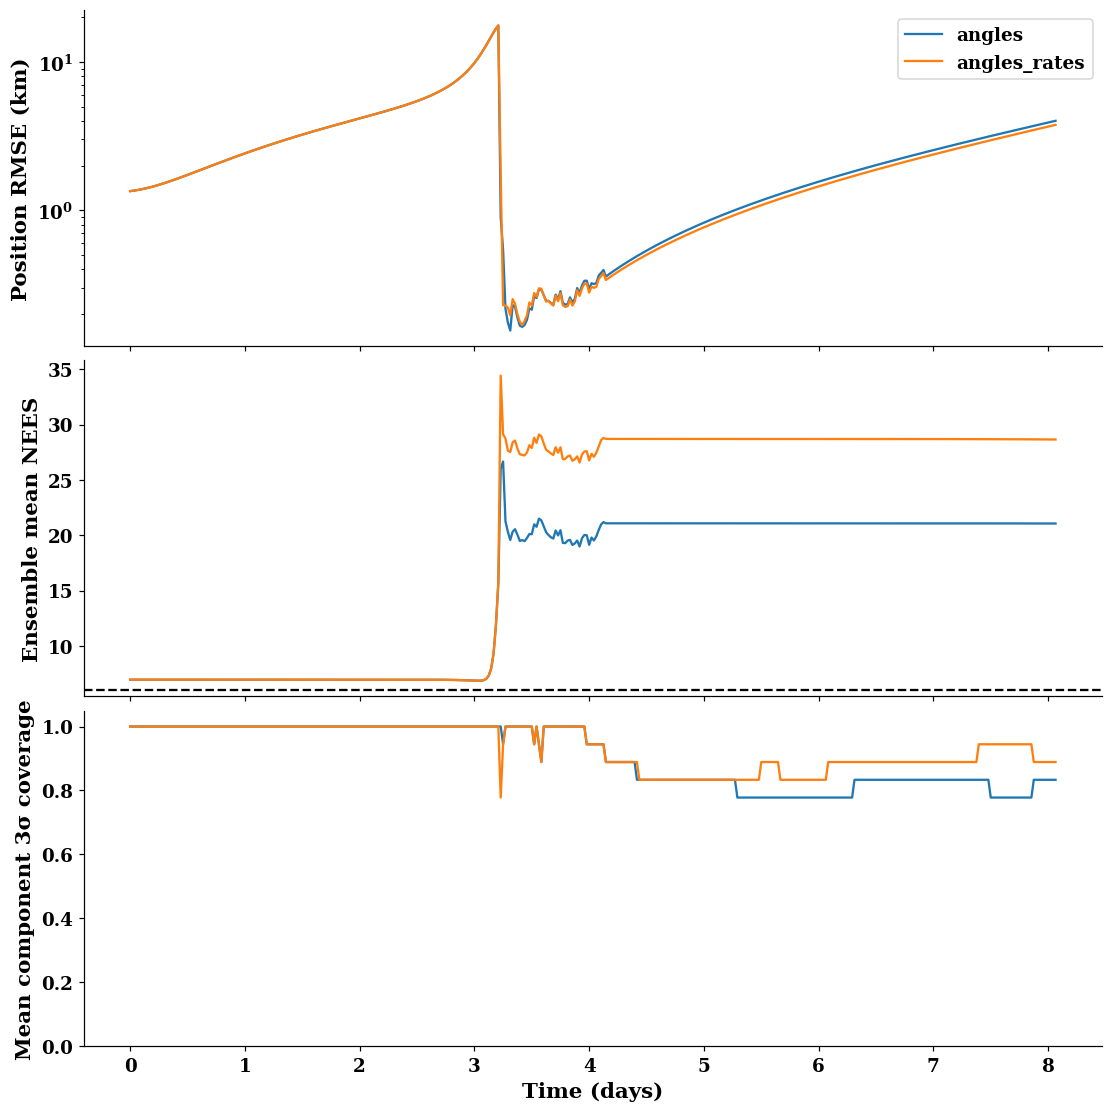

In [4]:
import numpy as np
import matplotlib.pyplot as plt
days = mc["times"] * cfg["time_unit_s"] / 86400
fig_mc, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True, layout="constrained")
for name in ["angles", "angles_rates"]:
    axes[0].semilogy(days, mc[name]["position_rmse_km"], label=name)
    axes[1].plot(days, mc[name]["mean_nees"], label=name)
    axes[2].plot(days, mc[name]["component_3sigma_coverage"].mean(axis=1), label=name)
axes[0].set_ylabel("Position RMSE (km)")
axes[1].set_ylabel("Ensemble mean NEES")
axes[1].axhline(6, color="black", ls="--", label="Six-state reference mean")
axes[2].set(ylabel="Mean component 3σ coverage", xlabel="Time (days)", ylim=(0, 1.05))
axes[0].legend()
for name in ["angles", "angles_rates"]:
    print(name, "Final NEES:", mc[name]["mean_nees"][-1],
          "Visible NIS mean:", np.nanmean(mc[name]["nis"]))

NEES/NIS confidence intervals require independent trial ensembles; time samples are correlated. This baseline compares measurement cases under one dynamics model. Higher-fidelity truth and alternative estimators are future comparisons, not implemented results.

In [5]:
from halo_tracking.plotting import export
export(fig_mc, ROOT / "results/comparison/monte_carlo.png")
output = ROOT / "results/comparison"
output.mkdir(parents=True, exist_ok=True)
arrays = {"times": mc["times"], "visible": mc["visible"]}
for name in ["angles", "angles_rates"]:
    for key, value in mc[name].items():
        arrays[name + "_" + key] = value
np.savez_compressed(output / "monte_carlo.npz", **arrays)

## Baseline finding
The initial three-trial run has final mean NEES well above six. The current covariance is not yet demonstrated to be statistically consistent. Investigate prior size, nonlinear behavior near lunar passage, cadence, and Monte Carlo convergence before using the uncertainty bounds for design decisions.